In [59]:
import pulp as plp
import matplotlib.pyplot as plt
from itertools import product

In [60]:
comprimentos_palete = [8, 50, 50]
larguras_palete = [6, 50, 40]

comprimentos_caixa = [3, 5, 7]
larguras_caixa = [2, 4, 6]

In [61]:
indice = 0
palete_comprimento = comprimentos_palete[indice]
palete_largura = larguras_palete[indice]

caixa_comprimento = comprimentos_caixa[indice]
caixa_largura = larguras_caixa[indice]

print(f"Dimensões do Palete: {palete_comprimento} x {palete_largura}")
print(f"Dimensões da Caixa: {caixa_comprimento} x {caixa_largura}")

Dimensões do Palete: 8 x 6
Dimensões da Caixa: 3 x 2


In [62]:
dimensoes_palete = [palete_comprimento, palete_largura]
L, W = sorted(dimensoes_palete, reverse=True) #garante que L >= W, já que o palete é retangular e o reverse=True garante que o maior valor seja L e o menor seja W
print(f"Dimensões classificadas do Palete: {L} x {W}")


Dimensões classificadas do Palete: 8 x 6


In [63]:
dimensoes_caixa = [caixa_comprimento, caixa_largura]
l_um, w_um = sorted(dimensoes_caixa, reverse=True) #garante que l >= w, já que a caixa é retangular e o reverse=True garante que o maior valor seja l e o menor seja w
print(f"Dimensões classificadas da Caixa: {l_um} x {w_um}")


Dimensões classificadas da Caixa: 3 x 2


In [64]:

l_dois, w_dois = dimensoes_caixa[::-1] #rotaciona a caixa 90 graus
#ou
#l_dois, w_dois = w_um, l_um #rotaciona a caixa 90 graus

print(f"Dimensões classificadas da Caixa (rotacionada): {l_dois} x {w_dois}")

Dimensões classificadas da Caixa (rotacionada): 2 x 3


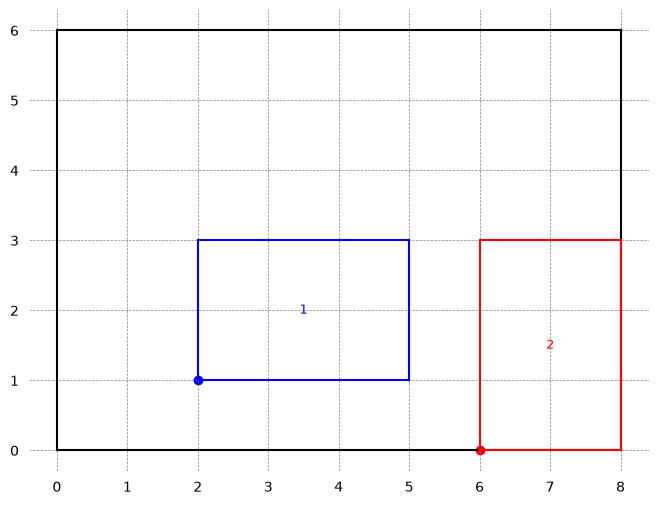

In [65]:
def plotar_caixa(botton_left: list,
                 l: int,
                 w: int,
                 color: str,
                 label: str):
    x0, y0 = botton_left
    plt.scatter(x=x0, y=y0, color=color)
    plt.plot([x0, x0 + l], [y0, y0], color=color)
    plt.plot([x0, x0], [y0, y0 + w], color=color)
    plt.plot([x0, x0 + l], [y0 + w, y0 + w], color=color)
    plt.plot([x0 + l, x0 + l], [y0, y0 + w], color=color)
    plt.text(x=x0 + l/2, y=y0 + w/2, s=label, color=color, fontsize=9, ha='center', va='center')

def plotar_palete(L: int, W: int):
    plt.figure(figsize=(8, 6), facecolor='white')
    plt.gca().set_facecolor("white") #estabelece a cor de fundo do gráfico como branco
    plt.grid(color='gray', linestyle='--', linewidth=0.5)
    plt.xticks(color="black")
    plt.yticks(color="black")
    plt.plot([0, L], [0, 0], "k-")
    plt.plot([0, 0], [0, W], "k-")
    plt.plot([0, L], [W, W], "k-")
    plt.plot([L, L], [0, W], "k-")

plotar_palete(L, W)
plotar_caixa(botton_left=[2, 1], l=3, w=2, color='blue', label='1')
plotar_caixa(botton_left=[6, 0], l=2, w=3, color='red', label='2')

In [66]:
f_um = lambda n_um, l_um, n_dois, l_dois: n_um * l_um + n_dois * l_dois

f_dois = lambda n_um, w_um, n_dois, w_dois: n_um * w_um + n_dois * w_dois

In [67]:
print(f_um(n_um=1, l_um=3, n_dois=2, l_dois=2))   # p <= L - w_um
print(f_dois(n_um=2, w_um=2, n_dois=0, w_dois=3)) # q <= W - w_um

7
4


0 0
1 0
2 0
0 1
1 1
0 2
0 3


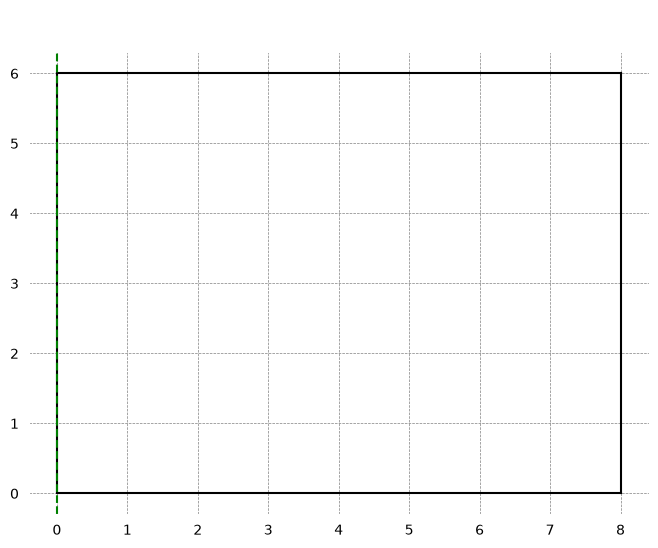

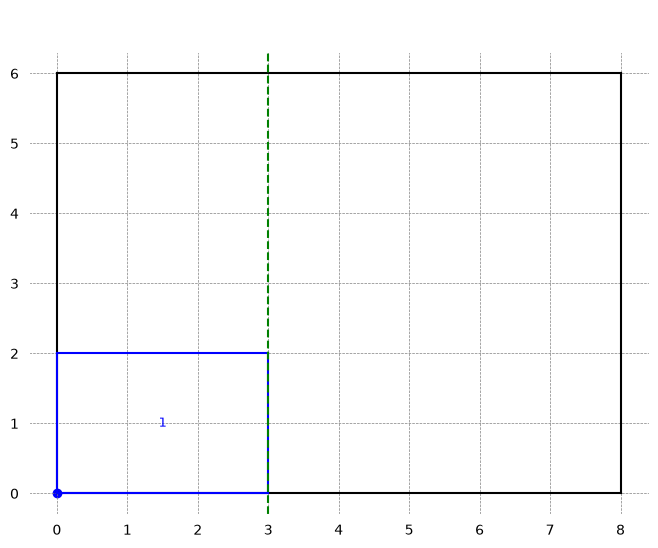

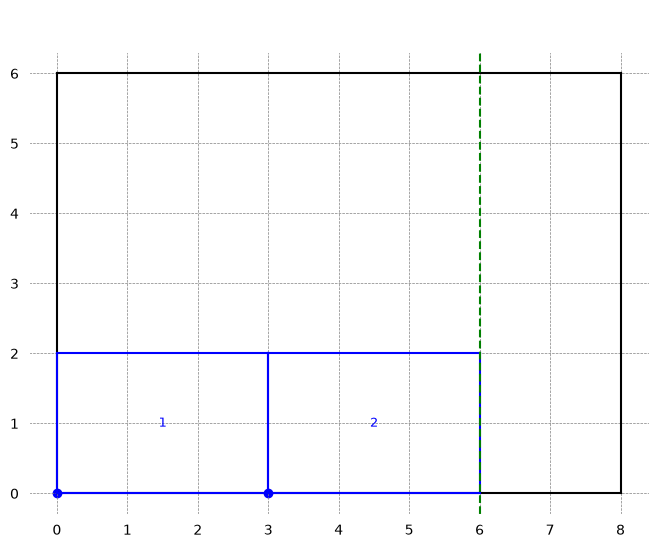

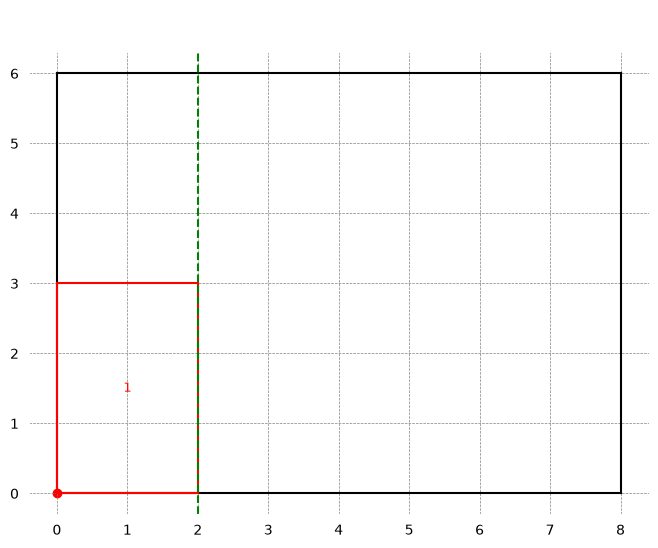

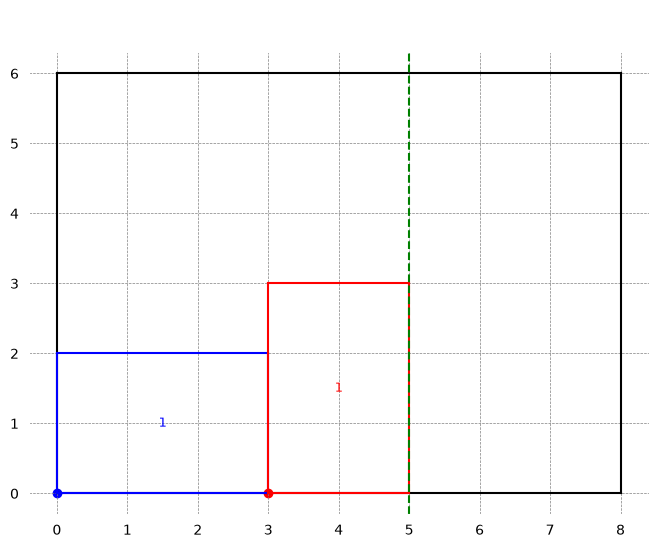

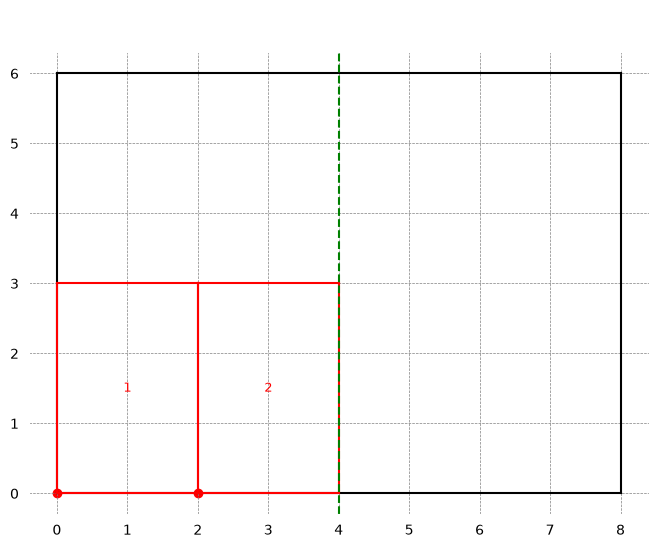

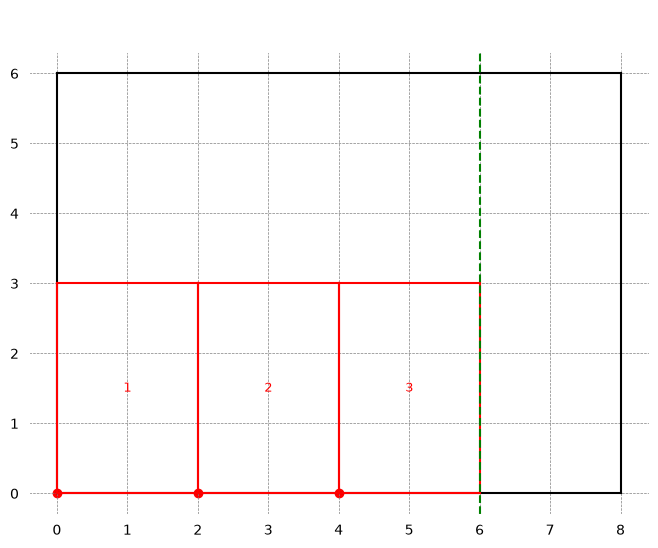

In [68]:
H = []
for n_dois, n_um in product(range(L), range(L)):
    #print(n_um, n_dois)
    p = f_um(n_um, l_um, n_dois, l_dois)

    if p <= L - w_um:
        print(n_um, n_dois)
        if p not in H: #evitar duplicatas nos resultados
            H.append(p)

        plotar_palete(L, W)

        for n in range(n_um):
            plotar_caixa(botton_left=[n*l_um, 0], l=l_um, w=w_um, color='blue', label=n + 1)

        for n in range(n_dois):
            plotar_caixa(botton_left=[n_um * l_um + n * l_dois, 0], l=l_dois, w=w_dois, color='red', label=n + 1)

        #print(n_um, n_dois, p)
        plt.axvline(x=p, color='green', linestyle='--')
        plt.title(f"{n_um = } | {n_dois = } | {p = }\n{H = }")
        plt.grid(color='gray', linestyle='--', linewidth=0.5)
        plt.gca().set_facecolor("white") #estabelece a cor de fundo do gráfico como branco
        

0 0
1 0
2 0
0 1


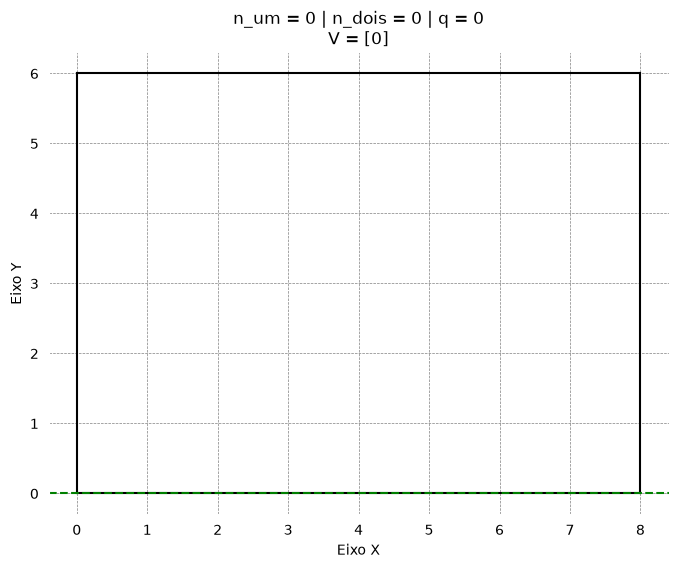

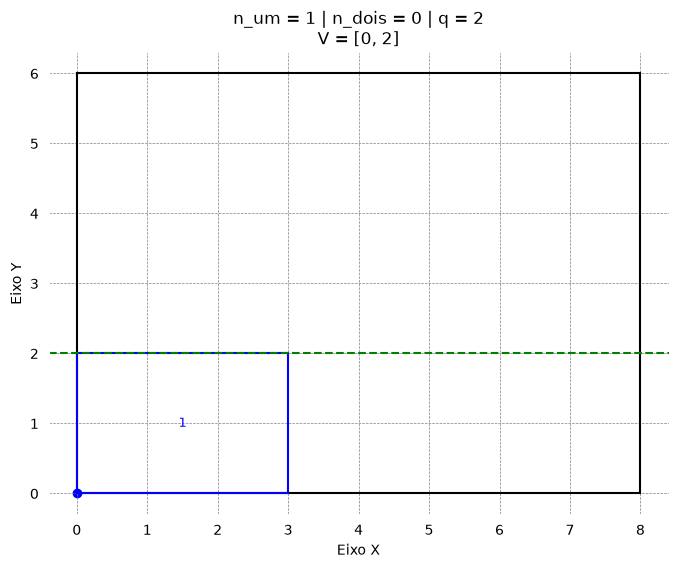

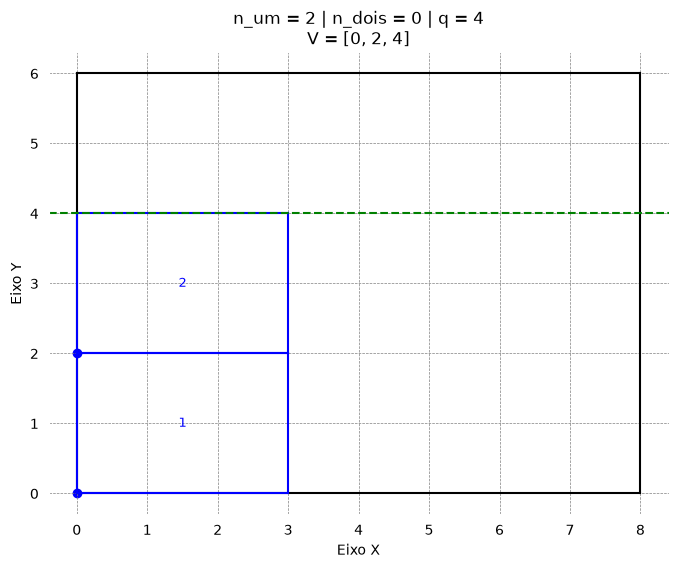

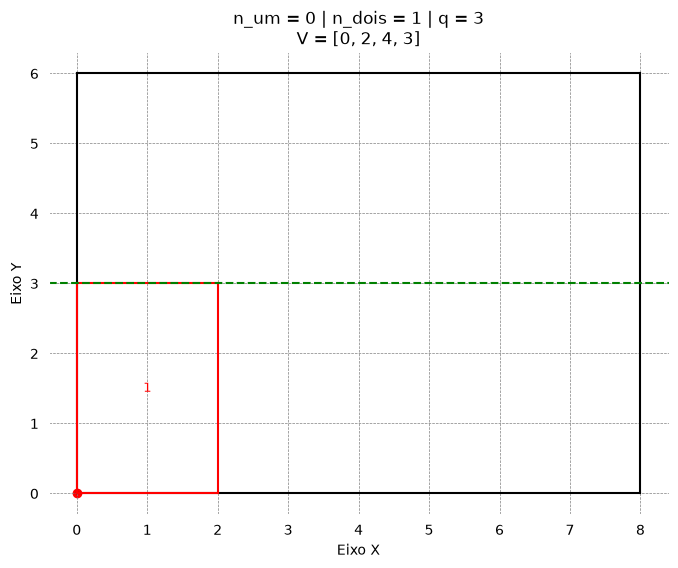

In [69]:
V = []
for n_dois, n_um in product(range(L), range(L)):
    #print(n_um, n_dois)
    q = f_dois(n_um, w_um, n_dois, w_dois)

    if q <= W - w_um:
        print(n_um, n_dois)
        if q not in V: #evitar duplicatas nos resultados
            V.append(q)

        plotar_palete(L, W)

        for n in range(n_um):
            plotar_caixa(botton_left=[0, n*w_um], l=l_um, w=w_um, color='blue', label=n + 1)

        for n in range(n_dois):
            plotar_caixa(botton_left=[0, n_um * w_um + n * w_dois], l=l_dois, w=w_dois, color='red', label=n + 1)

        #print(n_um, n_dois, q)
        plt.axhline(y=q, color='green', linestyle='--')
        plt.title(f"{n_um = } | {n_dois = } | {q = }\n{V = }", color="black")
        plt.grid(color='gray', linestyle='--', linewidth=0.5)
        plt.gca().set_facecolor("white") #estabelece a cor de fundo do gráfico como branco
        plt.gcf().patch.set_facecolor("white") #estabelece a cor de fundo da figura como branco
        plt.xlabel("Eixo X", color="black")
        plt.ylabel("Eixo Y", color="black")
        plt.xticks(color="black")
        plt.yticks(color="black")
        #plt.title(f"Palete: {L} x {W} | Caixa: {l_um} x {w_um} | Rotacionada: {l_dois} x {w_dois}", color="black")
        

In [70]:
H = sorted(H)
V = sorted(V)
print(H)
print(V)

[0, 2, 3, 4, 5, 6]
[0, 2, 3, 4]


In [71]:
lista_rs = list(product(H, V))
display(lista_rs)

[(0, 0),
 (0, 2),
 (0, 3),
 (0, 4),
 (2, 0),
 (2, 2),
 (2, 3),
 (2, 4),
 (3, 0),
 (3, 2),
 (3, 3),
 (3, 4),
 (4, 0),
 (4, 2),
 (4, 3),
 (4, 4),
 (5, 0),
 (5, 2),
 (5, 3),
 (5, 4),
 (6, 0),
 (6, 2),
 (6, 3),
 (6, 4)]

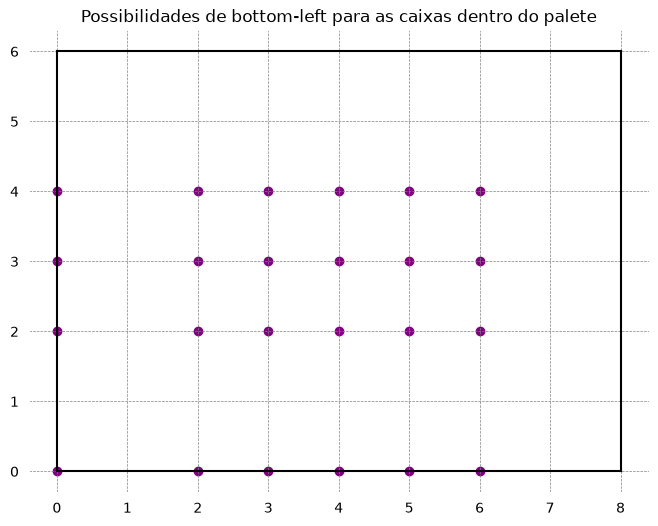

In [72]:
if indice == 0:
    plotar_palete(L, W)
    for r, s in lista_rs:
        plt.scatter(x=r, y=s, color='purple')

    plt.title("Possibilidades de bottom-left para as caixas dentro do palete", color="black")
    plt.gca().set_facecolor("white") #estabelece a cor de fundo do gráfico como branco
    plt.gcf().patch.set_facecolor("white") #estabelece a cor de fundo da figura como branco
    plt.grid(color='gray', linestyle='--', linewidth=0.5)
    plt.xticks(color="black")
    plt.yticks(color="black")
    plt.show()

In [73]:
ls = [l_um, l_dois]
ws = [w_um, w_dois]

In [74]:
i = 1
print(ls[i-1], ws[i-1])

3 2


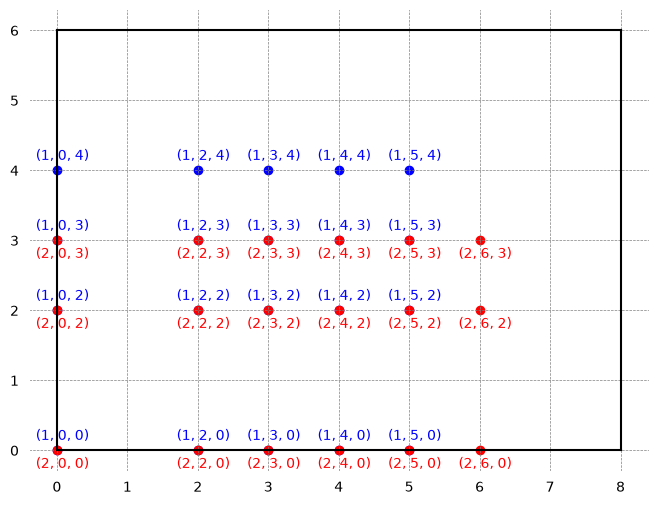

In [75]:
lista_variaveis = []
plotar_palete(L, W)
for (p, q), i  in product(lista_rs, [1,2]):
    #print(i, p, q)
    # i = 1 (caixa deitada)
    # i = 2 (caixa em pé)
    if p + ls[i-1] <= L and q + ws[i-1] <= W: #checa se a caixa cabe dentro do palete
        lista_variaveis.append((i, p, q)) #Igor comentou que deveria se chamar "lista_PQ"

        if indice == 0:
            cor = 'blue' if i == 1 else 'red'
            plt.scatter(x=p, y=q, color=cor) #plota o bottom-left da caixa dentro do palete

            if i == 1:
                plt.text(x=p -0.3, y=q + 0.15, s=f"({i}, {p}, {q})", color=cor, fontsize=10)
            else:
                plt.text(x=p -0.3, y=q - 0.25, s=f"({i}, {p}, {q})", color=cor, fontsize=10)
        

In [76]:
prob = plp.LpProblem(name="Palete-Caixa", sense=plp.LpMaximize)
display(prob)

Palete-Caixa:
MAXIMIZE
None
VARIABLES

In [77]:
dict_variaveis = plp.LpVariable.dicts(name="C", indices=lista_variaveis, lowBound=0, upBound=1, cat=plp.LpBinary)
# Foi usado plp.LpBinary, pois o problema é resolvido com 0 ou 1, não entre 0 e 1.
print(len(dict_variaveis))
display(dict_variaveis)


38


{(1, 0, 0): C_(1,_0,_0),
 (2, 0, 0): C_(2,_0,_0),
 (1, 0, 2): C_(1,_0,_2),
 (2, 0, 2): C_(2,_0,_2),
 (1, 0, 3): C_(1,_0,_3),
 (2, 0, 3): C_(2,_0,_3),
 (1, 0, 4): C_(1,_0,_4),
 (1, 2, 0): C_(1,_2,_0),
 (2, 2, 0): C_(2,_2,_0),
 (1, 2, 2): C_(1,_2,_2),
 (2, 2, 2): C_(2,_2,_2),
 (1, 2, 3): C_(1,_2,_3),
 (2, 2, 3): C_(2,_2,_3),
 (1, 2, 4): C_(1,_2,_4),
 (1, 3, 0): C_(1,_3,_0),
 (2, 3, 0): C_(2,_3,_0),
 (1, 3, 2): C_(1,_3,_2),
 (2, 3, 2): C_(2,_3,_2),
 (1, 3, 3): C_(1,_3,_3),
 (2, 3, 3): C_(2,_3,_3),
 (1, 3, 4): C_(1,_3,_4),
 (1, 4, 0): C_(1,_4,_0),
 (2, 4, 0): C_(2,_4,_0),
 (1, 4, 2): C_(1,_4,_2),
 (2, 4, 2): C_(2,_4,_2),
 (1, 4, 3): C_(1,_4,_3),
 (2, 4, 3): C_(2,_4,_3),
 (1, 4, 4): C_(1,_4,_4),
 (1, 5, 0): C_(1,_5,_0),
 (2, 5, 0): C_(2,_5,_0),
 (1, 5, 2): C_(1,_5,_2),
 (2, 5, 2): C_(2,_5,_2),
 (1, 5, 3): C_(1,_5,_3),
 (2, 5, 3): C_(2,_5,_3),
 (1, 5, 4): C_(1,_5,_4),
 (2, 6, 0): C_(2,_6,_0),
 (2, 6, 2): C_(2,_6,_2),
 (2, 6, 3): C_(2,_6,_3)}

In [78]:
#dict_variabveis.values()
#sum(dict_variabveis.values())
prob += sum(dict_variaveis.values())
display(prob)

Palete-Caixa:
MAXIMIZE
1*C_(1,_0,_0) + 1*C_(1,_0,_2) + 1*C_(1,_0,_3) + 1*C_(1,_0,_4) + 1*C_(1,_2,_0) + 1*C_(1,_2,_2) + 1*C_(1,_2,_3) + 1*C_(1,_2,_4) + 1*C_(1,_3,_0) + 1*C_(1,_3,_2) + 1*C_(1,_3,_3) + 1*C_(1,_3,_4) + 1*C_(1,_4,_0) + 1*C_(1,_4,_2) + 1*C_(1,_4,_3) + 1*C_(1,_4,_4) + 1*C_(1,_5,_0) + 1*C_(1,_5,_2) + 1*C_(1,_5,_3) + 1*C_(1,_5,_4) + 1*C_(2,_0,_0) + 1*C_(2,_0,_2) + 1*C_(2,_0,_3) + 1*C_(2,_2,_0) + 1*C_(2,_2,_2) + 1*C_(2,_2,_3) + 1*C_(2,_3,_0) + 1*C_(2,_3,_2) + 1*C_(2,_3,_3) + 1*C_(2,_4,_0) + 1*C_(2,_4,_2) + 1*C_(2,_4,_3) + 1*C_(2,_5,_0) + 1*C_(2,_5,_2) + 1*C_(2,_5,_3) + 1*C_(2,_6,_0) + 1*C_(2,_6,_2) + 1*C_(2,_6,_3) + 0
VARIABLES
0 <= C_(1,_0,_0) <= 1 Integer
0 <= C_(1,_0,_2) <= 1 Integer
0 <= C_(1,_0,_3) <= 1 Integer
0 <= C_(1,_0,_4) <= 1 Integer
0 <= C_(1,_2,_0) <= 1 Integer
0 <= C_(1,_2,_2) <= 1 Integer
0 <= C_(1,_2,_3) <= 1 Integer
0 <= C_(1,_2,_4) <= 1 Integer
0 <= C_(1,_3,_0) <= 1 Integer
0 <= C_(1,_3,_2) <= 1 Integer
0 <= C_(1,_3,_3) <= 1 Integer
0 <= C_(1,_3,_4) <= 1 Integ

In [79]:
# aqui apenas checamos o número de variáveis e restrições. Restrições ainda não criadas até esse ponto.
print(f"Qtd variaveis: {prob.numVariables()}")
print(f"Qtd variaveis: {prob.numConstraints()}")

Qtd variaveis: 38
Qtd variaveis: 0


In [80]:
def ponto_dentro_caixa(ponto_rs: tuple, 
                       ponto_pq: tuple,
                         l: int, w:int) -> bool:
    r, s = ponto_rs
    p, q = ponto_pq
    return p <= r < p + l and q <= s < q + w
print(ponto_dentro_caixa((6, 2), #Chute de posições apenas para testar a função
                         (6, 0),
                         l=ls[0], w=ws[0]))

False


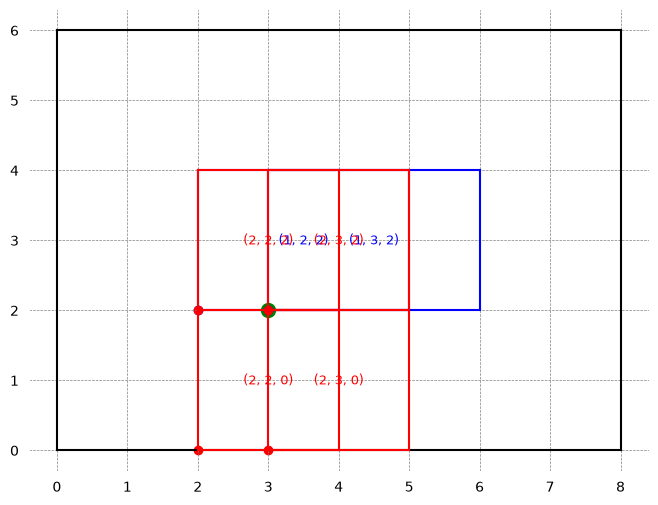

In [81]:
plotar_palete(L, W)
r, s = lista_rs[9] # indice 9 da lista rs
plt.scatter(x=r, y=s, color="green", s=100)
caixas_sobrepostas = []
for i, p, q in lista_variaveis:
    if ponto_dentro_caixa((r, s),
                          (p, q),
                          l=ls[i-1], w=ws[i-1]):
        plotar_caixa((p, q), ls[i-1], ws[1-1],
                    color="blue" if i == 1 else "red",
                    label=f"{i, p, q}")


In [84]:

# r, s = lista_rs[9] , não vamos mais acessar um a um manualmente, por tanto usamos 'for'
for r, s in lista_rs:
    caixas_sobrepostas = []
    for i, p, q in lista_variaveis:
        if ponto_dentro_caixa((r, s),
                            (p, q),
                            l=ls[i-1], w=ws[i-1]):
            caixas_sobrepostas.append(dict_variaveis[(i, p, q)])
    # print(sum(caixas_sobrepostas))
    prob += sum(caixas_sobrepostas) <= 1, f"Restricao 1.{n}"
    n += 1

    
        

In [ ]:
# Contagem total de restrições do problema
print(len(prob.constraints))
# ou
print(prob.numConstraints())

print(prob.numVariables())
print(prob)

24
24
38


In [90]:
qtd_maxima_caixas = (L * W)  // (l_um * w_um)
print(qtd_maxima_caixas)

8


In [91]:
prob += sum(dict_variaveis.values()) <= qtd_maxima_caixas, "Restricao_2"
display(prob)

Palete-Caixa:
MAXIMIZE
1*C_(1,_0,_0) + 1*C_(1,_0,_2) + 1*C_(1,_0,_3) + 1*C_(1,_0,_4) + 1*C_(1,_2,_0) + 1*C_(1,_2,_2) + 1*C_(1,_2,_3) + 1*C_(1,_2,_4) + 1*C_(1,_3,_0) + 1*C_(1,_3,_2) + 1*C_(1,_3,_3) + 1*C_(1,_3,_4) + 1*C_(1,_4,_0) + 1*C_(1,_4,_2) + 1*C_(1,_4,_3) + 1*C_(1,_4,_4) + 1*C_(1,_5,_0) + 1*C_(1,_5,_2) + 1*C_(1,_5,_3) + 1*C_(1,_5,_4) + 1*C_(2,_0,_0) + 1*C_(2,_0,_2) + 1*C_(2,_0,_3) + 1*C_(2,_2,_0) + 1*C_(2,_2,_2) + 1*C_(2,_2,_3) + 1*C_(2,_3,_0) + 1*C_(2,_3,_2) + 1*C_(2,_3,_3) + 1*C_(2,_4,_0) + 1*C_(2,_4,_2) + 1*C_(2,_4,_3) + 1*C_(2,_5,_0) + 1*C_(2,_5,_2) + 1*C_(2,_5,_3) + 1*C_(2,_6,_0) + 1*C_(2,_6,_2) + 1*C_(2,_6,_3) + 0
SUBJECT TO
Restricao_1.0: C_(1,_0,_0) + C_(2,_0,_0) <= 1

Restricao_1.1: C_(1,_0,_2) + C_(2,_0,_0) + C_(2,_0,_2) <= 1

Restricao_1.2: C_(1,_0,_2) + C_(1,_0,_3) + C_(2,_0,_2) + C_(2,_0,_3) <= 1

Restricao_1.3: C_(1,_0,_3) + C_(1,_0,_4) + C_(2,_0,_2) + C_(2,_0,_3) <= 1

Restricao_1.4: C_(1,_0,_0) + C_(1,_2,_0) + C_(2,_2,_0) <= 1

Restricao_1.5: C_(1,_0,_2) + C_(1,_2,

In [92]:

print(prob.numConstraints())

print(prob.numVariables())


25
38


In [93]:
solver = plp.getSolver("PULP_CBC_CMD", timeLimit=None)

In [94]:
prob.solve(solver)

1

In [ ]:
display(plp.LpStatus)  # Para conhecer as possibilidades de respostas

{0: 'Not Solved',
 1: 'Optimal',
 -1: 'Infeasible',
 -2: 'Unbounded',
 -3: 'Undefined'}

In [ ]:
print(prob.variables())
# Mas qual pode ser posta em uma posição válida?

[C_(1,_0,_0), C_(1,_0,_2), C_(1,_0,_3), C_(1,_0,_4), C_(1,_2,_0), C_(1,_2,_2), C_(1,_2,_3), C_(1,_2,_4), C_(1,_3,_0), C_(1,_3,_2), C_(1,_3,_3), C_(1,_3,_4), C_(1,_4,_0), C_(1,_4,_2), C_(1,_4,_3), C_(1,_4,_4), C_(1,_5,_0), C_(1,_5,_2), C_(1,_5,_3), C_(1,_5,_4), C_(2,_0,_0), C_(2,_0,_2), C_(2,_0,_3), C_(2,_2,_0), C_(2,_2,_2), C_(2,_2,_3), C_(2,_3,_0), C_(2,_3,_2), C_(2,_3,_3), C_(2,_4,_0), C_(2,_4,_2), C_(2,_4,_3), C_(2,_5,_0), C_(2,_5,_2), C_(2,_5,_3), C_(2,_6,_0), C_(2,_6,_2), C_(2,_6,_3)]


In [ ]:
print((prob.variables()[0].varValue))
print((prob.variables()[0].name, prob.variables()[0].varValue))
print(prob.objective.value()) # total de soluções viáveis

1.0
('C_(1,_0,_0)', 1.0)
8.0


In [100]:
dict_traducao = \
    dict(zip(dict_variaveis.values(),
             dict_variaveis.keys()))
display(dict_traducao)

{C_(1,_0,_0): (1, 0, 0),
 C_(2,_0,_0): (2, 0, 0),
 C_(1,_0,_2): (1, 0, 2),
 C_(2,_0,_2): (2, 0, 2),
 C_(1,_0,_3): (1, 0, 3),
 C_(2,_0,_3): (2, 0, 3),
 C_(1,_0,_4): (1, 0, 4),
 C_(1,_2,_0): (1, 2, 0),
 C_(2,_2,_0): (2, 2, 0),
 C_(1,_2,_2): (1, 2, 2),
 C_(2,_2,_2): (2, 2, 2),
 C_(1,_2,_3): (1, 2, 3),
 C_(2,_2,_3): (2, 2, 3),
 C_(1,_2,_4): (1, 2, 4),
 C_(1,_3,_0): (1, 3, 0),
 C_(2,_3,_0): (2, 3, 0),
 C_(1,_3,_2): (1, 3, 2),
 C_(2,_3,_2): (2, 3, 2),
 C_(1,_3,_3): (1, 3, 3),
 C_(2,_3,_3): (2, 3, 3),
 C_(1,_3,_4): (1, 3, 4),
 C_(1,_4,_0): (1, 4, 0),
 C_(2,_4,_0): (2, 4, 0),
 C_(1,_4,_2): (1, 4, 2),
 C_(2,_4,_2): (2, 4, 2),
 C_(1,_4,_3): (1, 4, 3),
 C_(2,_4,_3): (2, 4, 3),
 C_(1,_4,_4): (1, 4, 4),
 C_(1,_5,_0): (1, 5, 0),
 C_(2,_5,_0): (2, 5, 0),
 C_(1,_5,_2): (1, 5, 2),
 C_(2,_5,_2): (2, 5, 2),
 C_(1,_5,_3): (1, 5, 3),
 C_(2,_5,_3): (2, 5, 3),
 C_(1,_5,_4): (1, 5, 4),
 C_(2,_6,_0): (2, 6, 0),
 C_(2,_6,_2): (2, 6, 2),
 C_(2,_6,_3): (2, 6, 3)}

In [103]:
variaveis_organizadas = []
for variavel in prob.variables():
    #print(variavel.name, variavel.varValue)
    if variavel.varValue > 0:
        var_traduzida = dict_traducao[variavel]
        variaveis_organizadas.append(var_traduzida)
display(variaveis_organizadas)

[(1, 0, 0),
 (1, 0, 2),
 (1, 0, 4),
 (1, 3, 0),
 (1, 3, 2),
 (1, 3, 4),
 (2, 6, 0),
 (2, 6, 3)]

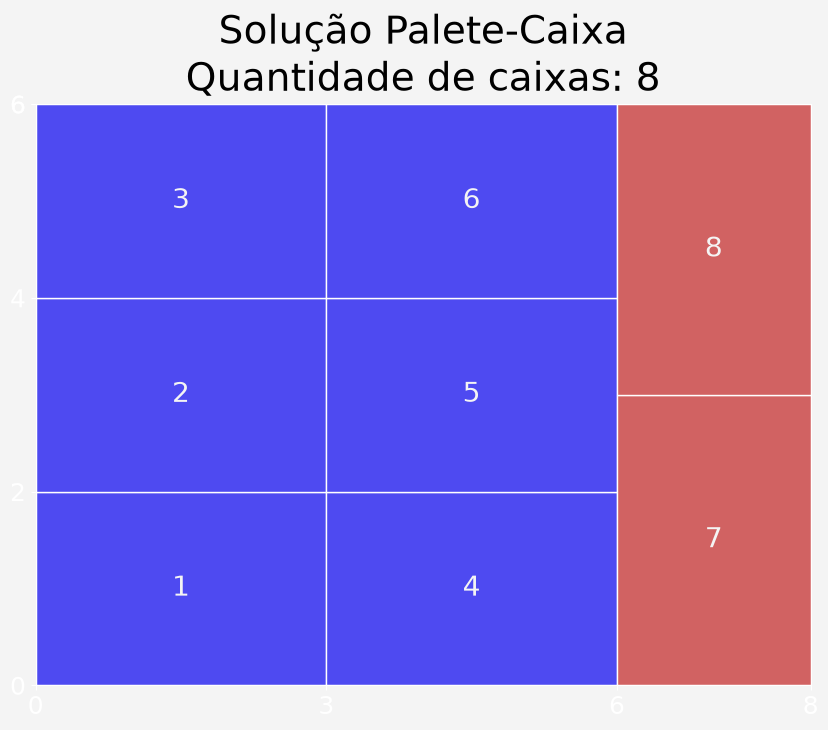

In [108]:
fig, ax = plt.subplots(figsize=(10, 10))
fig.set_facecolor('#f4f4f4')

a = plt.gca()
a.set_xticks(list(range(0, L + 1, l_um)) + [L])
a.set_yticks(list(range(0, W + 1, w_um)) + [W])
a.set_xticklabels(a.get_xticks())
a.set_yticklabels(a.get_yticks())

qtd_caixas = len(variaveis_organizadas)
for indice_caixa, variavel_organizada in enumerate(variaveis_organizadas, 1):
    i, p, q = variavel_organizada
    
    ax.add_patch(plt.Rectangle(xy=(p, q), 
                               width=ls[i - 1], 
                               height=ws[i - 1], 
                               facecolor="#4e4af1" if i == 1 else "#d16262", 
                               edgecolor="white", lw=1,
                               alpha=1,))

    plt.text(x=p + ls[i - 1] / 2, 
             y=q + ws[i - 1] / 2, 
             s=f"{indice_caixa}", 
             fontsize=20,
             color="#f4f4f4",
             ha="center", 
             va="center")

ax.set_title(f"Solução Palete-Caixa\nQuantidade de caixas: {qtd_caixas}",
                fontsize=28,
                color="black")

ax.set_xlim(0, L)
ax.set_ylim(0, W)
ax.set_aspect("equal")

ax.xaxis.set_tick_params(labelsize=18)
ax.yaxis.set_tick_params(labelsize=18)

In [ ]:
from copy import deepcopy  # Fundamental quando trabalhamos com listas, pois são mutáveis. Então fazemos uma cópia e congelamos os i, p, q's
solucoes = [deepcopy(variaveis_organizadas)]

In [110]:
from random import random, seed
seed(42)

n = 0 
for variavel in prob.variables():
    if variavel.varValue > 0:

        if random() > 0.2:
            continue  # Esse continue volta para o "for". Se ele não entrar no if (> 0.2) ele vai pro print
        print(variavel)
        prob += variavel == 0, f"Restricao_3.{n}"
        n += 1

C_(1,_0,_2)
C_(2,_6,_3)


In [111]:
print(prob.numConstraints())

print(prob.numVariables())

27
38


In [112]:
prob.solve(solver)

1

In [113]:
variaveis_organizadas = []
for variavel in prob.variables():
    #print(variavel.name, variavel.varValue)
    if variavel.varValue > 0:
        var_traduzida = dict_traducao[variavel]
        variaveis_organizadas.append(var_traduzida)
display(variaveis_organizadas)

[(1, 2, 0),
 (1, 2, 2),
 (1, 2, 4),
 (1, 5, 0),
 (1, 5, 2),
 (1, 5, 4),
 (2, 0, 0),
 (2, 0, 3)]

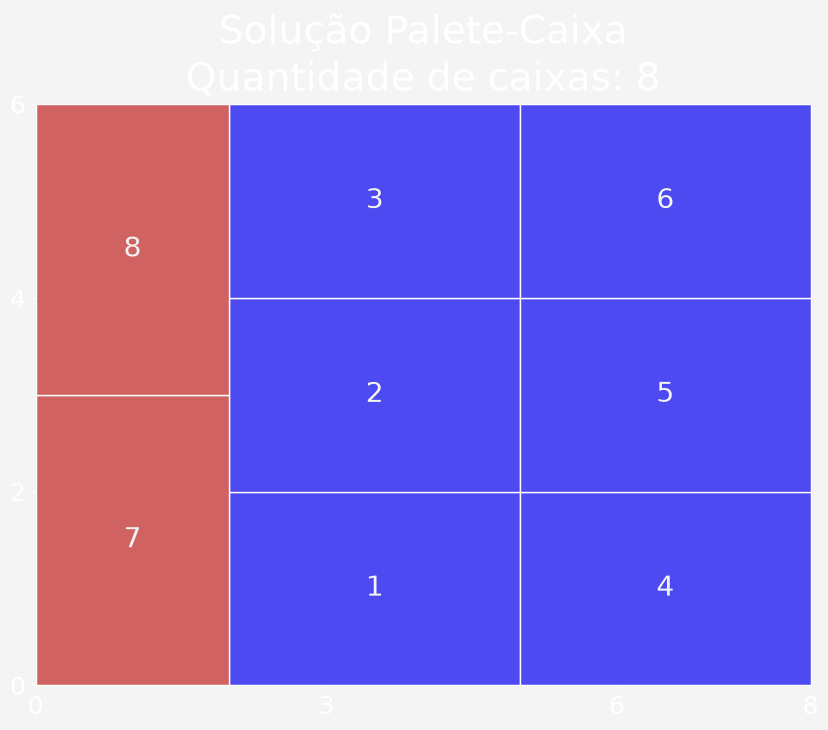

In [114]:
fig, ax = plt.subplots(figsize=(10, 10))
fig.set_facecolor('#f4f4f4')

a = plt.gca()
a.set_xticks(list(range(0, L + 1, l_um)) + [L])
a.set_yticks(list(range(0, W + 1, w_um)) + [W])
a.set_xticklabels(a.get_xticks())
a.set_yticklabels(a.get_yticks())

qtd_caixas = len(variaveis_organizadas)
for indice_caixa, variavel_organizada in enumerate(variaveis_organizadas, 1):
    i, p, q = variavel_organizada
    
    ax.add_patch(plt.Rectangle(xy=(p, q), 
                               width=ls[i - 1], 
                               height=ws[i - 1], 
                               facecolor="#4e4af1" if i == 1 else "#d16262", 
                               edgecolor="white", lw=1,
                               alpha=1,))

    plt.text(x=p + ls[i - 1] / 2, 
             y=q + ws[i - 1] / 2, 
             s=f"{indice_caixa}", 
             fontsize=20,
             color="#f4f4f4",
             ha="center", 
             va="center")

ax.set_title(f"Solução Palete-Caixa\nQuantidade de caixas: {qtd_caixas}",
                fontsize=28)

ax.set_xlim(0, L)
ax.set_ylim(0, W)
ax.set_aspect("equal")

ax.xaxis.set_tick_params(labelsize=18)
ax.yaxis.set_tick_params(labelsize=18)